# Eigenstrapping validation

This notebook validates `nulls.eigenstrap` by examining the statistical properties of nulls computed on a spherical surface.

In [1]:
from importlib.resources import as_file, files

import matplotlib.pyplot as plt
import numpy as np
from nsbutils.plotting import plot_surf

from neuromodes import EigenSolver
from neuromodes.io import fetch_example_surf
from neuromodes.stats import cdistw, pdistw


In [2]:
# Configuration
res = '32k'
n_modes = 15**2  # First 15 eigengroups
n_nulls = 1000
seed = 365

We start by loading a mesh, initiating the `EigenSolver` class, and computing the eigenmodes.

In [4]:
hemi = 'L'
structure = 'sphere'
mesh, _ = fetch_example_surf(res=res, hemi=hemi, structure=structure)
mesh.v = mesh.v / 100.0  # Scale vertices to unit sphere
solver = EigenSolver(mesh).eigs(n_modes)

# Synthetic data for testing
v = mesh.v
map0 = np.sin(v[:, 0]*np.pi) + np.sin(v[:, 1]*2*np.pi) + np.cos(v[:, 2]*3*np.pi)
map1 = np.cos(v[:, 0]*np.pi) + np.cos(v[:, 1]*2*np.pi) + np.cos(v[:, 2]*3*np.pi)

We can then call the `eigenstrap` class method to generate a null distribution. This may take a few minutes depending on the number of CPU cores available.

In [5]:
# Calculate nulls
nulls = solver.eigenstrap(
    data=map0,
    n_nulls=n_nulls,
    seed=seed,
    randomize=False,
    residual=None, 
    rotation_method='qr' # to compare with eigenstrapping.ipynb (which always uses 'scipy' method)
)
print(nulls.shape)

(32492, 1000)


Now let's visualize the original map and a few null maps.

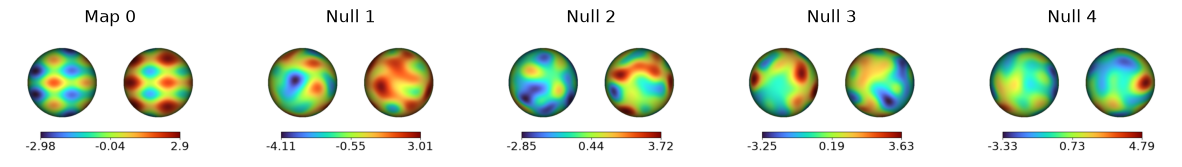

In [6]:
# Plot nulls
lh_surfpath = files('neuromodes.data') / f'sp-human_tpl-fsLR_den-{res}_hemi-{hemi}_{structure}.surf.gii'

with as_file(lh_surfpath) as lh_surfpath:
    fig1, axs = plt.subplots(1, 5, figsize=(15, 6))
    axs = axs.ravel()
    for i, ax in enumerate(axs):
        if i == 0:
            data = map0
            title = "Map 0"
        else:
            data = nulls[:, i-1]
            title = f"Null {i}"

        color_range = (np.nanpercentile(data, 5), np.nanpercentile(data, 95))

        plot_surf(lh_surfpath, data, cmap="turbo", color_range=color_range, ax=ax, cbar=True)
        ax.set_title(title)


We can check that the power spectrum distribution between the original and the nulls is exactly preserved on the sphere (it will only be approximately preserved on surfaces where the group relationship is not exact). 

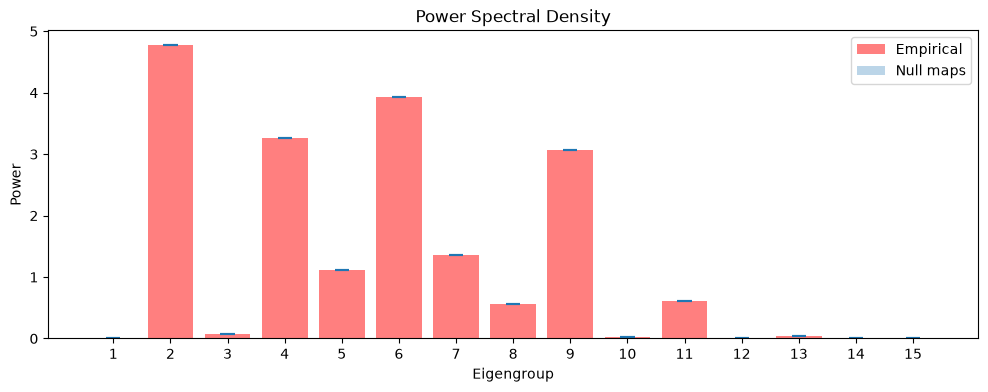

In [7]:
# PSD within each eigengroup should be preserved
group_indices = np.floor(np.sqrt(np.arange(n_modes))).astype(int)
n_groups = group_indices.max() + 1

beta0 = solver.decompose(map0)
psd0 = np.bincount(group_indices, weights=beta0.ravel()**2)

beta1 = solver.decompose(nulls)
psd1 = np.array([np.bincount(group_indices, weights=beta1[:, i].ravel()**2) for i in range(n_nulls)])

fig, axs = plt.subplots(figsize=(12,4))
axs.bar(range(1,n_groups+1), psd0, color='red', alpha=0.5)
violin_parts = axs.violinplot(psd1, positions=range(1,n_groups+1))
axs.legend([axs.patches[0], violin_parts['bodies'][0]], ['Empirical', 'Null maps'])
axs.set_title("Power Spectral Density")
axs.set_xlabel("Eigengroup")
axs.set_xticks(range(1,n_groups+1))
axs.set_ylabel("Power")
plt.show()

Let's also plot the distribution of correlation coefficients between every pair of nulls.

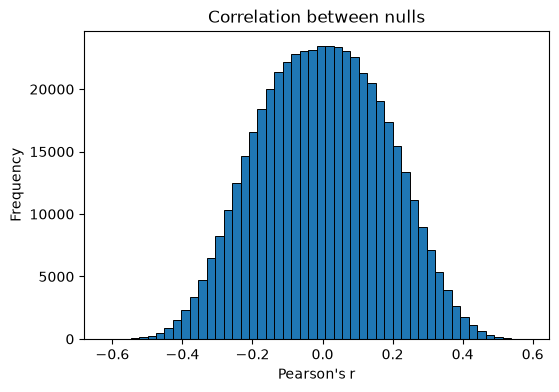

In [8]:
# Plot null correlation distribution
inter_null_corrs = 1-pdistw(nulls, metric='correlation', mass=solver.mass)
fig2, ax2 = plt.subplots(figsize=(6, 4))
ax2.hist(inter_null_corrs, bins=50, edgecolor="black", linewidth=0.7)
ax2.set_title("Correlation between nulls")
ax2.set_xlabel("Pearson's r")
ax2.set_ylabel("Frequency")
plt.show()

Now we can use our nulls to test whether the map0 is significantly correlated with another similar looking map.

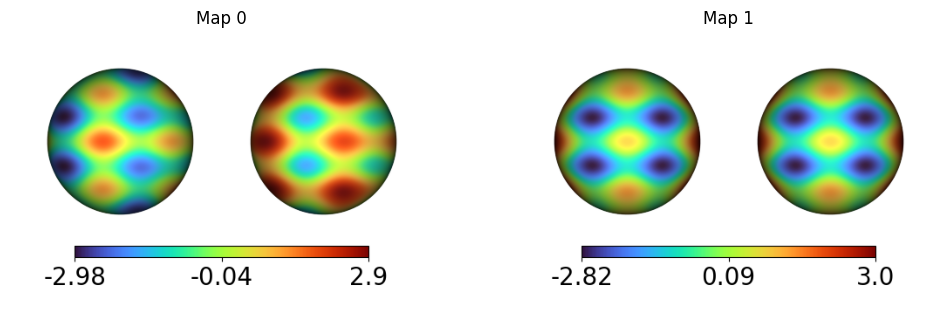

Observed correlation between map0 and map1: 0.2505


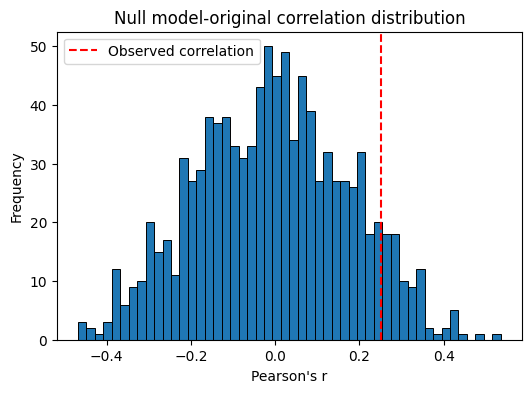

p-value: 0.1818


In [ ]:
# Visualise map0 and map1
fig, ax_i = plt.subplots(1, 2, figsize=(12, 6))
with as_file(lh_surfpath) as lh_surfpath:
    plot_surf(lh_surfpath, map0, cmap="turbo", ax=ax_i[0], cbar=True)
    plot_surf(lh_surfpath, map1, cmap="turbo", ax=ax_i[1], cbar=True)
ax_i[0].set_title("Map 0")
ax_i[1].set_title("Map 1")
plt.show()

# Compute correlation between map0 and map1
corr = 1-cdistw(map0, map1, metric='correlation', mass=solver.mass)[0, 0]
print(f"Observed correlation between map0 and map1: {corr:.4f}")

# Compute correlation between map0 and nulls
null_corrs = 1-cdistw(map0, nulls, metric='correlation', mass=solver.mass)[0]

# Plot correlation distributions
fig, ax_i = plt.subplots(figsize=(6, 4))
ax_i.hist(null_corrs, bins=50, edgecolor="black", linewidth=0.7)
ax_i.axvline(corr, color="red", linestyle="--", label="Observed correlation")
ax_i.set_title("Null model-original correlation distribution")
ax_i.set_xlabel("Pearson's r")
ax_i.set_ylabel("Frequency")
# ax_i.set_xlim(-0.6, 0.6)
ax_i.legend()
plt.show()

pvalue = (np.sum(np.abs(null_corrs) >= np.abs(corr)) + 1) / (n_nulls + 1)
print(f"p-value: {pvalue:.4f}")